# Data Understanding

## Introduction

The purpose of this notebook is to understand the characteristics, structure, and quality of the datasets used in this study before any preprocessing is performed.

The project uses four datasets:

- Bitcoin historical market data
- Ethereum historical market data
- Google Trends search interest
- Crypto Fear & Greed Index

This notebook focuses on examining the datasets to identify potential data quality issues, understand the variables, and assess whether the datasets are suitable for the forecasting task. No data cleaning or transformation is performed at this stage.

## Import libraries

In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

Matplotlib is building the font cache; this may take a moment.


## Load datasets



The four datasets are loaded into Python using the Pandas library. These datasets represent the raw data collected during the data collection stage and will be examined individually throughout this notebook.

In [2]:

btc = pd.read_csv("../data/raw/btc-usd-max.csv")
eth = pd.read_csv("../data/raw/eth-usd-max.csv")
google_trends = pd.read_csv("../data/raw/google_trends.csv")
fear_greed = pd.read_csv("../data/raw/fear_greed.csv")

## Dataset_Overview

The first step is to examine the overall structure of each dataset.

The following information is inspected:

- Number of observations
- Number of variables
- Column names
- Data types
- Missing values
- Duplicate records

This provides an initial understanding of the datasets before further analysis.

In [3]:
# Create a helper function for dataset overview

def dataset_overview(df, name):
    print("=" * 50)
    print(name)
    print("=" * 50)
    print("Rows:", df.shape[0])
    print("Columns:", df.shape[1])
    print("\nColumn Names:")
    print(df.columns.tolist())
    print("\nData Types:")
    print(df.dtypes)
    print("\nMissing Values:")
    print(df.isnull().sum())
    print("\nDuplicate Rows:")
    print(df.duplicated().sum())

In [4]:
# 4. Overview of each dataset

dataset_overview(btc, "Bitcoin Dataset")
dataset_overview(eth, "Ethereum Dataset")
dataset_overview(google_trends, "Google Trends Dataset")
dataset_overview(fear_greed, "Fear and Greed Dataset")

Bitcoin Dataset
Rows: 4810
Columns: 4

Column Names:
['event_date', 'close_price_usd', 'market_cap_usd', 'volume_usd']

Data Types:
event_date             str
close_price_usd    float64
market_cap_usd     float64
volume_usd         float64
dtype: object

Missing Values:
event_date         0
close_price_usd    1
market_cap_usd     0
volume_usd         0
dtype: int64

Duplicate Rows:
0
Ethereum Dataset
Rows: 3980
Columns: 4

Column Names:
['event_date', 'close_price_usd', 'market_cap_usd', 'volume_usd']

Data Types:
event_date             str
close_price_usd    float64
market_cap_usd     float64
volume_usd         float64
dtype: object

Missing Values:
event_date         0
close_price_usd    1
market_cap_usd     0
volume_usd         0
dtype: int64

Duplicate Rows:
0
Google Trends Dataset
Rows: 1801
Columns: 3

Column Names:
['date', 'Bitcoin', 'Ethereum']

Data Types:
date          str
Bitcoin     int64
Ethereum    int64
dtype: object

Missing Values:
date        0
Bitcoin     0
Ethereum

## Display Sample Records

Displaying the first and last five records provides an initial understanding of the structure and content of each dataset. This also helps verify that the datasets have been imported correctly.

### Bitcoin

In [6]:
btc.head()

,event_date,close_price_usd,market_cap_usd,volume_usd
0,2013-04-28 00:00:00 UTC,135.30,1.500518e+09,0.0
1,2013-04-29 00:00:00 UTC,141.96,1.575032e+09,0.0
2,2013-04-30 00:00:00 UTC,135.30,1.501657e+09,0.0
3,2013-05-01 00:00:00 UTC,117.00,1.298952e+09,0.0
4,2013-05-02 00:00:00 UTC,103.43,1.148668e+09,0.0


In [7]:
btc.tail()

,event_date,close_price_usd,market_cap_usd,volume_usd
4805,2026-06-27 00:00:00 UTC,59953.104326,1.202007e+12,1.609358e+10
4806,2026-06-28 00:00:00 UTC,59505.975883,1.193065e+12,1.681314e+10
4807,2026-06-29 00:00:00 UTC,60142.264258,1.205848e+12,3.186555e+10
4808,2026-06-30 00:00:00 UTC,58573.008037,1.174410e+12,3.214112e+10
4809,2026-07-01 00:00:00 UTC,NaN,1.204271e+12,3.570361e+10


### Ethereum

In [9]:
eth.head()

,event_date,close_price_usd,market_cap_usd,volume_usd
0,2015-08-07 00:00:00 UTC,2.831620,0.000000e+00,9.062200e+04
1,2015-08-08 00:00:00 UTC,1.330750,8.033948e+07,3.680700e+05
2,2015-08-10 00:00:00 UTC,0.687586,4.155631e+07,4.004641e+05
3,2015-08-11 00:00:00 UTC,1.067379,6.453901e+07,1.518998e+06
4,2015-08-12 00:00:00 UTC,1.256613,7.601326e+07,2.073893e+06


In [10]:
eth.tail()

,event_date,close_price_usd,market_cap_usd,volume_usd
3975,2026-06-27 00:00:00 UTC,1572.034025,1.897186e+11,6.491580e+09
3976,2026-06-28 00:00:00 UTC,1570.617566,1.895476e+11,6.702220e+09
3977,2026-06-29 00:00:00 UTC,1609.867069,1.942844e+11,1.211541e+10
3978,2026-06-30 00:00:00 UTC,1570.068856,1.894813e+11,9.677245e+09
3979,2026-07-01 00:00:00 UTC,NaN,1.941995e+11,1.093762e+10


### Google Trends

In [11]:
google_trends.head()

,date,Bitcoin,Ethereum
0,2021-06-01,75,18
1,2021-06-02,69,18
2,2021-06-03,72,19
3,2021-06-04,76,17
4,2021-06-05,67,16


In [12]:
google_trends.tail()

,date,Bitcoin,Ethereum
1796,2026-05-02,20,3
1797,2026-05-03,20,3
1798,2026-05-04,23,3
1799,2026-05-05,24,4
1800,2026-05-06,27,4


### Fear_Greed

In [13]:
fear_greed.head()

,Date,Fear_Greed_Index,Classification
0,2021-06-01,20,Extreme Fear
1,2021-06-02,23,Extreme Fear
2,2021-06-03,24,Extreme Fear
3,2021-06-04,27,Fear
4,2021-06-05,24,Extreme Fear


In [14]:
fear_greed.tail()

,Date,Fear_Greed_Index,Classification
1821,2026-05-28,22,Extreme Fear
1822,2026-05-29,23,Extreme Fear
1823,2026-05-30,23,Extreme Fear
1824,2026-05-31,28,Fear
1825,2026-06-01,29,Fear


## Dataset Structure

To examine the structure, data types, and completeness of each dataset.
This helps verify that the datasets have been loaded correctly and are suitable for further analysis before preprocessing.


In [41]:
print("=" * 60)
print("Bitcoin Dataset")
print("=" * 60)
btc.info()

print("\n" + "=" * 60)
print("Ethereum Dataset")
print("=" * 60)
eth.info()

print("\n" + "=" * 60)
print("Google Trends Dataset")
print("=" * 60)
google_trends.info()

print("\n" + "=" * 60)
print("Fear & Greed Dataset")
print("=" * 60)
fear_greed.info()

Bitcoin Dataset
<class 'pandas.DataFrame'>
RangeIndex: 4810 entries, 0 to 4809
Data columns (total 4 columns):
 #   Column           Non-Null Count  Dtype              
---  ------           --------------  -----              
 0   event_date       4810 non-null   datetime64[us, UTC]
 1   close_price_usd  4809 non-null   float64            
 2   market_cap_usd   4810 non-null   float64            
 3   volume_usd       4810 non-null   float64            
dtypes: datetime64[us, UTC](1), float64(3)
memory usage: 150.4 KB

Ethereum Dataset
<class 'pandas.DataFrame'>
RangeIndex: 3980 entries, 0 to 3979
Data columns (total 4 columns):
 #   Column           Non-Null Count  Dtype              
---  ------           --------------  -----              
 0   event_date       3980 non-null   datetime64[us, UTC]
 1   close_price_usd  3979 non-null   float64            
 2   market_cap_usd   3980 non-null   float64            
 3   volume_usd       3980 non-null   float64            
dtypes: dateti

## Interpretation

The Bitcoin and Ethereum datasets each contain four variables: the date, closing price, market capitalisation, and trading volume. Most of the data is complete, with only one missing value in the `close_price_usd` column of each dataset. The data types are appropriate, with dates stored as datetime and financial values stored as numeric variables.

The Google Trends dataset contains the date and daily search interest for Bitcoin and Ethereum. All records are complete, and no missing values were found.

The Crypto Fear & Greed dataset contains the date, the daily Fear & Greed Index score, and the corresponding sentiment classification. All variables are complete and use suitable data types.

Overall, the datasets have been loaded successfully and have a suitable structure for this study. Only one missing price value was found in both the Bitcoin and Ethereum datasets. This issue will be addressed during the Data Preprocessing stage.

## Date Column Overview

In [ ]:

print(btc.columns)
print(eth.columns)
print(google_trends.columns)
print(fear_greed.columns)

Index(['event_date', 'close_price_usd', 'market_cap_usd', 'volume_usd'], dtype='str')
Index(['event_date', 'close_price_usd', 'market_cap_usd', 'volume_usd'], dtype='str')
Index(['date', 'Bitcoin', 'Ethereum'], dtype='str')
Index(['Date', 'Fear_Greed_Index', 'Classification'], dtype='str')


## Interpretation

The output shows that the four datasets use different names for their date columns. The Bitcoin and Ethereum datasets use `event_date`, the Google Trends dataset uses `date`, and the Crypto Fear & Greed dataset uses `Date`. Although the column names differ, they all represent the observation date. These columns will be standardised to a common name during the Data Preprocessing stage to ensure that the datasets can be accurately aligned and merged.

## Date Range Analysis

In [42]:
btc["event_date"] = pd.to_datetime(btc["event_date"])
eth["event_date"] = pd.to_datetime(eth["event_date"])
google_trends["date"] = pd.to_datetime(google_trends["date"])
fear_greed["Date"] = pd.to_datetime(fear_greed["Date"])

In [43]:
print("BTC Date Range:", btc["event_date"].min(), "to", btc["event_date"].max())
print("ETH Date Range:", eth["event_date"].min(), "to", eth["event_date"].max())
print("Google Trends Date Range:", google_trends["date"].min(), "to", google_trends["date"].max())
print("Fear & Greed Date Range:", fear_greed["Date"].min(), "to", fear_greed["Date"].max())

BTC Date Range: 2013-04-28 00:00:00+00:00 to 2026-07-01 00:00:00+00:00
ETH Date Range: 2015-08-07 00:00:00+00:00 to 2026-07-01 00:00:00+00:00
Google Trends Date Range: 2021-06-01 00:00:00 to 2026-05-06 00:00:00
Fear & Greed Date Range: 2021-06-01 00:00:00 to 2026-06-01 00:00:00


### Interpretation

The Bitcoin dataset covers the period from **28 April 2013** to **1 July 2026**, while the Ethereum dataset covers **7 August 2015** to **1 July 2026**. The Google Trends dataset covers **1 June 2021** to **6 May 2026**, and the Crypto Fear & Greed dataset covers **1 June 2021** to **1 June 2026**.

Although the Bitcoin and Ethereum datasets contain a longer historical record, this study focuses on the common study period from **1 June 2021 to 1 June 2026**. During the Data Preprocessing stage, the Bitcoin and Ethereum datasets will be filtered to this date range so that all four datasets cover the same period and can be accurately aligned and merged for analysis.

## Duplicate Date Check

To identify whether any duplicate dates exist in each dataset.
Duplicate dates can affect data alignment and lead to incorrect results when the datasets are merged and analysed.

In [24]:
print("BTC duplicate dates:", btc["event_date"].duplicated().sum())
print("ETH duplicate dates:", eth["event_date"].duplicated().sum())
print("Google Trends duplicate dates:", google_trends["date"].duplicated().sum())
print("Fear & Greed duplicate dates:", fear_greed["Date"].duplicated().sum())

BTC duplicate dates: 0
ETH duplicate dates: 0
Google Trends duplicate dates: 0
Fear & Greed duplicate dates: 0


### Interpretation

No duplicate dates were found in any of the four datasets. This indicates that each observation is unique, and the datasets are suitable for alignment and merging during the Data Preprocessing stage.

## Missing Values Analysis

This section checks each dataset for missing values to assess its completeness. Detecting missing values before preprocessing helps ensure that the data is suitable for analysis and allows any issues to be addressed before the datasets are merged.

In [25]:
def missing_percentage(df, name):
    print("=" * 50)
    print(name)
    print("=" * 50)
    missing = df.isnull().sum()
    percent = (missing / len(df)) * 100
    result = pd.DataFrame({
        "Missing Values": missing,
        "Percentage": percent
    })
    print(result)

missing_percentage(btc, "Bitcoin Dataset")
missing_percentage(eth, "Ethereum Dataset")
missing_percentage(google_trends, "Google Trends Dataset")
missing_percentage(fear_greed, "Fear and Greed Dataset")

Bitcoin Dataset
                 Missing Values  Percentage
event_date                    0     0.00000
close_price_usd               1     0.02079
market_cap_usd                0     0.00000
volume_usd                    0     0.00000
Ethereum Dataset
                 Missing Values  Percentage
event_date                    0    0.000000
close_price_usd               1    0.025126
market_cap_usd                0    0.000000
volume_usd                    0    0.000000
Google Trends Dataset
          Missing Values  Percentage
date                   0         0.0
Bitcoin                0         0.0
Ethereum               0         0.0
Fear and Greed Dataset
                  Missing Values  Percentage
Date                           0         0.0
Fear_Greed_Index               0         0.0
Classification                 0         0.0


### Interpretation
The results show that the Google Trends and Crypto Fear & Greed datasets contain no missing values. The Bitcoin and Ethereum datasets each contain only one missing value in the `close_price_usd` column, representing a very small percentage of the data. Overall, the datasets are highly complete and suitable for further analysis. These minor missing values will be addressed during the Data Preprocessing stage.

## Descriptive statistics

This section summarises the key statistical characteristics of the numerical variables in each dataset. The descriptive statistics provide an overview of the data distribution and help identify the range and variability of the values before further analysis.

In [44]:


print("=" * 60)
print("Bitcoin Dataset")
print("=" * 60)
display(btc.describe())

print("=" * 60)
print("Ethereum Dataset")
print("=" * 60)
display(eth.describe())

print("=" * 60)
print("Google Trends Dataset")
print("=" * 60)
display(google_trends.describe())

print("=" * 60)
print("Fear & Greed Dataset")
print("=" * 60)
display(fear_greed.describe())

Bitcoin Dataset


,close_price_usd,market_cap_usd,volume_usd
count,4809.000000,4.810000e+03,4.810000e+03
mean,25860.550727,5.014351e+11,1.648943e+17
std,31926.899368,6.343529e+11,3.815335e+18
min,67.809000,7.713681e+08,0.000000e+00
25%,697.277362,1.032437e+10,6.372483e+08
50%,9466.961781,1.705816e+11,1.456911e+10
75%,42475.543221,8.162765e+11,3.088526e+10
max,124773.508231,2.486073e+12,9.554126e+19


Ethereum Dataset


,close_price_usd,market_cap_usd,volume_usd
count,3979.000000,3.980000e+03,3.980000e+03
mean,1375.306872,1.627956e+11,7.502562e+13
std,1314.647300,1.587176e+11,1.579055e+15
min,0.432979,0.000000e+00,8.707480e+04
25%,181.113301,1.924951e+10,1.306874e+09
50%,1143.533536,1.319760e+11,9.248329e+09
75%,2365.551913,2.831951e+11,1.786588e+10
max,4829.225542,5.828170e+11,3.686174e+16


Google Trends Dataset


,date,Bitcoin,Ethereum
count,1801,1801.000000,1801.000000
mean,2023-11-18 00:00:00,45.008884,8.063853
min,2021-06-01 00:00:00,16.000000,2.000000
25%,2022-08-25 00:00:00,31.000000,5.000000
50%,2023-11-18 00:00:00,43.000000,7.000000
75%,2025-02-10 00:00:00,57.000000,10.000000
max,2026-05-06 00:00:00,100.000000,50.000000
std,NaN,17.626714,5.158470


Fear & Greed Dataset


,Date,Fear_Greed_Index
count,1826,1826.000000
mean,2023-11-30 19:39:45.542168,45.644578
min,2021-06-01 00:00:00,5.000000
25%,2022-08-31 06:00:00,26.000000
50%,2023-11-30 12:00:00,48.000000
75%,2025-03-01 18:00:00,66.000000
max,2026-06-01 00:00:00,94.000000
std,NaN,21.489804


### Interpretation

The descriptive statistics provide an overview of the numerical variables in each dataset. The Bitcoin and Ethereum datasets show a wide range of values for closing price, market capitalisation, and trading volume, reflecting the high volatility of cryptocurrency markets over time.

The Google Trends dataset indicates that search interest for Bitcoin is generally higher than for Ethereum during the study period, while the Crypto Fear & Greed Index shows that market sentiment varies considerably, with values ranging from **5** (Extreme Fear) to **94** (Extreme Greed).

Overall, the descriptive statistics confirm that the datasets capture substantial variation in market behaviour, public interest, and investor sentiment, making them suitable for further analysis and forecasting.

## Distribution of Sentiment Categories

This section examines the distribution of the sentiment categories in the Crypto Fear & Greed dataset. It shows how the observations are distributed across different market sentiment categories during the study period.

In [30]:
fear_greed["Classification"].value_counts()

Classification
Greed            547
Fear             442
Extreme Fear     433
Neutral          289
Extreme Greed    115
Name: count, dtype: int64

### Interpretation

The results show that **Greed** is the most common market sentiment during the study period, followed by **Fear** and **Extreme Fear**. **Neutral** occurs less frequently, while **Extreme Greed** is the least common category. This indicates that cryptocurrency market sentiment varied over time, with periods of both optimism and uncertainty.

## Visualisation of Market Sentiment Distribution

This section visualises the distribution of market sentiment categories in the Crypto Fear & Greed dataset. The chart provides a clear comparison of how frequently each sentiment category occurs during the study period.

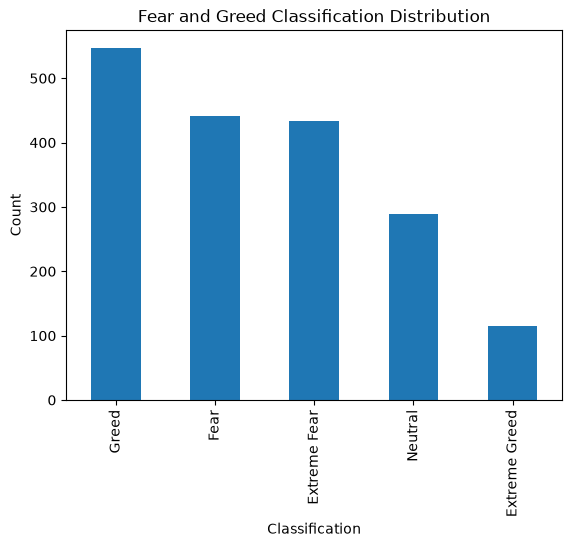

In [31]:
fear_greed["Classification"].value_counts().plot(kind="bar")
plt.title("Fear and Greed Classification Distribution")
plt.xlabel("Classification")
plt.ylabel("Count")
plt.show()

### Interpretation

The bar chart shows that **Greed** is the most frequent market sentiment, followed by **Fear** and **Extreme Fear**. **Neutral** occurs less often, while **Extreme Greed** is the least common category. Overall, the results indicate that investor sentiment fluctuated throughout the study period, with market conditions more frequently reflecting optimism than extreme optimism.

## Data Frequency Check

This section examines the frequency of observations in each dataset by calculating the time difference between consecutive dates. This helps confirm whether the data has been collected at consistent time intervals before the datasets are merged.

In [36]:
def check_frequency(df, date_column, dataset_name):

    # Convert the date column to datetime
    df[date_column] = pd.to_datetime(df[date_column])

    # Sort by date
    df = df.sort_values(date_column)

    # Calculate the difference between consecutive dates
    frequency = df[date_column].diff().value_counts()

    # Display the results
    print("=" * 50)
    print(dataset_name)
    print("=" * 50)
    print(frequency.head())
    print()


# Check data frequency for each dataset
check_frequency(btc, "event_date", "Bitcoin Dataset")
check_frequency(eth, "event_date", "Ethereum Dataset")
check_frequency(google_trends, "date", "Google Trends Dataset")
check_frequency(fear_greed, "Date", "Fear & Greed Dataset")

Bitcoin Dataset
event_date
1 days    4806
2 days       3
Name: count, dtype: int64

Ethereum Dataset
event_date
1 days    3977
2 days       2
Name: count, dtype: int64

Google Trends Dataset
date
1 days    1800
Name: count, dtype: int64

Fear & Greed Dataset
Date
1 days    1824
2 days       1
Name: count, dtype: int64



### Interpretation

The results show that all four datasets are recorded at a **daily frequency**, with a one-day interval between consecutive observations. This indicates that the datasets share a consistent temporal resolution and can be aligned using the date column during the Data Preprocessing stage.

## Negative Values Check

This section checks the numerical variables in each dataset for negative values. Identifying negative values helps ensure that the data is valid and highlights any values that may require further investigation before analysis.

In [40]:
def check_negative_values(df, dataset_name):

    # Select numerical columns
    numeric_columns = df.select_dtypes(include=["int64", "float64"]).columns

    # Display dataset name
    print("=" * 50)
    print(dataset_name)
    print("=" * 50)

    # Check each numerical column
    for column in numeric_columns:

        negative_values = (df[column] < 0).sum()

        print(f"{column}: {negative_values} negative values")

    print()


# Check negative values for each dataset
check_negative_values(btc, "Bitcoin Dataset")
check_negative_values(eth, "Ethereum Dataset")
check_negative_values(google_trends, "Google Trends Dataset")
check_negative_values(fear_greed, "Fear & Greed Dataset")

Bitcoin Dataset
close_price_usd: 0 negative values
market_cap_usd: 0 negative values
volume_usd: 0 negative values

Ethereum Dataset
close_price_usd: 0 negative values
market_cap_usd: 0 negative values
volume_usd: 0 negative values

Google Trends Dataset
Bitcoin: 0 negative values
Ethereum: 0 negative values

Fear & Greed Dataset
Fear_Greed_Index: 0 negative values



### Interpretation

No negative values were identified in any of the numerical variables across the Bitcoin, Ethereum, Google Trends, and Crypto Fear & Greed datasets. This indicates that the datasets are free from invalid negative observations and are suitable for further preprocessing and analysis.

## Data Quality Summary

The data quality assessment shows that all four datasets are of good quality and suitable for analysis. No duplicate records, duplicate dates, or negative values were identified, and only two missing values were found in the Bitcoin and Ethereum datasets. Overall, the datasets require only minor preprocessing before they are merged.

In [49]:
# Improved Data Quality Summary

data_quality_summary = pd.DataFrame({

    "Dataset": [
        "Bitcoin",
        "Ethereum",
        "Google Trends",
        "Fear & Greed"
    ],

    "Number of Rows": [
        btc.shape[0],
        eth.shape[0],
        google_trends.shape[0],
        fear_greed.shape[0]
    ],

    "Number of Columns": [
        btc.shape[1],
        eth.shape[1],
        google_trends.shape[1],
        fear_greed.shape[1]
    ],

    "Missing Values": [
        btc.isnull().sum().sum(),
        eth.isnull().sum().sum(),
        google_trends.isnull().sum().sum(),
        fear_greed.isnull().sum().sum()
    ],

    "Duplicate Rows": [
        btc.duplicated().sum(),
        eth.duplicated().sum(),
        google_trends.duplicated().sum(),
        fear_greed.duplicated().sum()
    ],

    "Duplicate Dates": [
        btc["event_date"].duplicated().sum(),
        eth["event_date"].duplicated().sum(),
        google_trends["date"].duplicated().sum(),
        fear_greed["Date"].duplicated().sum()
    ],

    "Frequency": [
        "Daily",
        "Daily",
        "Daily",
        "Daily"
    ],

    "Invalid Negative Values": [
        (btc.select_dtypes(include=["number"]) < 0).sum().sum(),
        (eth.select_dtypes(include=["number"]) < 0).sum().sum(),
        (google_trends.select_dtypes(include=["number"]) < 0).sum().sum(),
        (fear_greed.select_dtypes(include=["number"]) < 0).sum().sum()
    ]

})

display(data_quality_summary)

data_quality_summary.to_csv(
    "../results/tables/data_quality_summary.csv",
    index=False
)

,Dataset,Number of Rows,Number of Columns,Missing Values,Duplicate Rows,Duplicate Dates,Frequency,Invalid Negative Values
0,Bitcoin,4810,4,1,0,0,Daily,0
1,Ethereum,3980,4,1,0,0,Daily,0
2,Google Trends,1801,3,0,0,0,Daily,0
3,Fear & Greed,1826,3,0,0,0,Daily,0


### Interpretation

The data quality assessment confirms that all four datasets are suitable for further analysis. Only two missing values were identified in the Bitcoin and Ethereum datasets, while no duplicate records, duplicate dates, or negative values were found. All datasets follow a consistent daily frequency, requiring only minor preprocessing before they are merged.

## Data Dictionary
This section provides a data dictionary describing the variables used in each dataset. It summarises the meaning, data type, and measurement unit of every variable to improve the transparency and reproducibility of the analysis.

In [50]:
# Improved Data Dictionary

data_dictionary = pd.DataFrame({

    "Dataset": [
        "Bitcoin", "Bitcoin", "Bitcoin", "Bitcoin",
        "Ethereum", "Ethereum", "Ethereum", "Ethereum",
        "Google Trends", "Google Trends", "Google Trends",
        "Fear & Greed", "Fear & Greed", "Fear & Greed"
    ],

    "Variable": [
        "event_date",
        "close_price_usd",
        "market_cap_usd",
        "volume_usd",
        "event_date",
        "close_price_usd",
        "market_cap_usd",
        "volume_usd",
        "date",
        "Bitcoin",
        "Ethereum",
        "Date",
        "Fear_Greed_Index",
        "Classification"
    ],

    "Description": [
        "Observation date",
        "Daily closing price",
        "Daily market capitalisation",
        "Daily trading volume",
        "Observation date",
        "Daily closing price",
        "Daily market capitalisation",
        "Daily trading volume",
        "Observation date",
        "Google search interest for Bitcoin",
        "Google search interest for Ethereum",
        "Observation date",
        "Crypto Fear & Greed Index score",
        "Market sentiment classification"
    ],

    "Data Type": [
        "Datetime", "Float", "Float", "Float",
        "Datetime", "Float", "Float", "Float",
        "Datetime", "Integer", "Integer",
        "Datetime", "Integer", "String"
    ],

    "Unit / Scale": [
        "Date", "USD", "USD", "USD",
        "Date", "USD", "USD", "USD",
        "Date", "0–100", "0–100",
        "Date", "0–100", "Categorical"
    ]

})

display(data_dictionary)

data_dictionary.to_csv(
    "../results/tables/data_dictionary.csv",
    index=False
)

,Dataset,Variable,Description,Data Type,Unit / Scale
0,Bitcoin,event_date,Observation date,Datetime,Date
1,Bitcoin,close_price_usd,Daily closing price,Float,USD
2,Bitcoin,market_cap_usd,Daily market capitalisation,Float,USD
3,Bitcoin,volume_usd,Daily trading volume,Float,USD
4,Ethereum,event_date,Observation date,Datetime,Date
5,Ethereum,close_price_usd,Daily closing price,Float,USD
6,Ethereum,market_cap_usd,Daily market capitalisation,Float,USD
7,Ethereum,volume_usd,Daily trading volume,Float,USD
8,Google Trends,date,Observation date,Datetime,Date
9,Google Trends,Bitcoin,Google search interest for Bitcoin,Integer,0–100


### Interpretation

The data dictionary provides a clear description of the variables included in each dataset. It confirms that the datasets contain the required financial, search interest, and market sentiment variables needed for the subsequent preprocessing, analysis, and forecasting stages.